In [84]:
!pip install xgboost -q

In [85]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

In [29]:
df=pd.read_csv("/content/Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [31]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [35]:
print(df['Exited'].value_counts(normalize=True)*100)

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


In [41]:
print(df['Geography'].value_counts(normalize=True)*100)

Geography
France     50.14
Germany    25.09
Spain      24.77
Name: proportion, dtype: float64


In [37]:
df.duplicated().sum()

np.int64(0)

In [39]:
print(df.dtypes)

RowNumber            int64
CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object


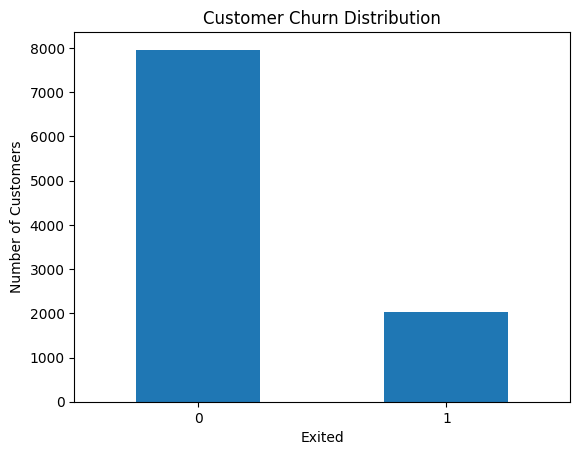

In [42]:
import matplotlib.pyplot as plt

df["Exited"].value_counts().plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Exited")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [50]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [48]:
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (10000, 11)

Data Types:
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

Missing Values:
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Duplicate Rows: 0


In [53]:
numerical_cols = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
CreditScore,10000.0,650.528800,96.653299,350.00,584.00,652.000,718.0000,850.00
Age,10000.0,38.921800,10.487806,18.00,32.00,37.000,44.0000,92.00
Tenure,10000.0,5.012800,2.892174,0.00,3.00,5.000,7.0000,10.00
Balance,10000.0,76485.889288,62397.405202,0.00,0.00,97198.540,127644.2400,250898.09
NumOfProducts,10000.0,1.530200,0.581654,1.00,1.00,1.000,2.0000,4.00
EstimatedSalary,10000.0,100090.239881,57510.492818,11.58,51002.11,100193.915,149388.2475,199992.48


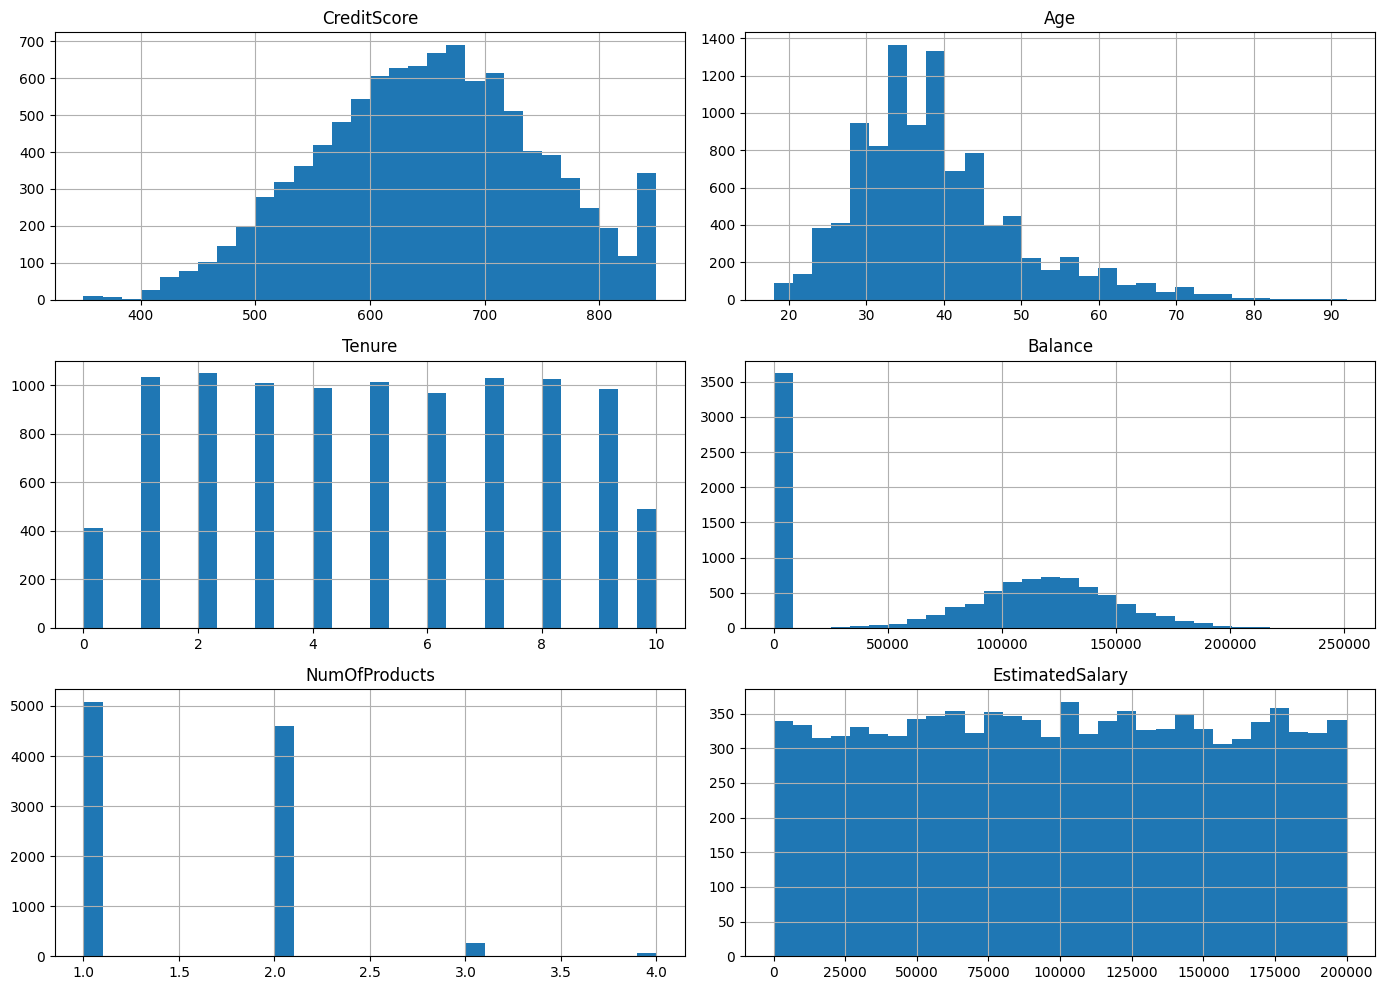

In [54]:
df[numerical_cols].hist(
    figsize=(14, 10),
    bins=30
)

plt.tight_layout()
plt.show()

In [56]:
categorical_cols = [
    "Geography",
    "Gender"
]

In [57]:
for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


Geography
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Gender
Gender
Male      5457
Female    4543
Name: count, dtype: int64


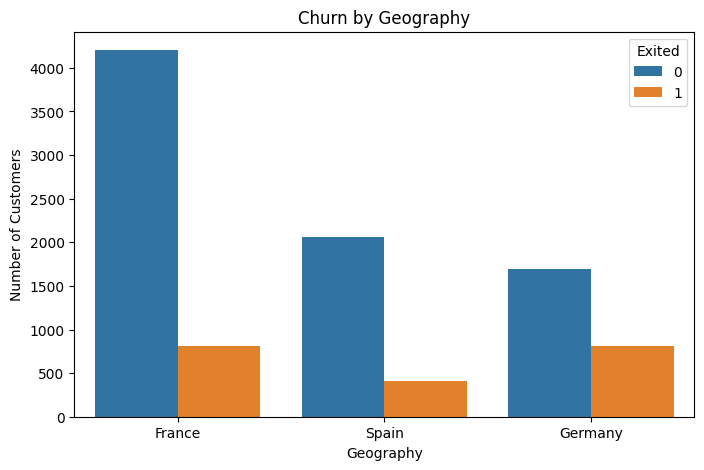

In [51]:
import seaborn as sns
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="Geography",
    hue="Exited"
)
plt.title("Churn by Geography")
plt.xlabel("Geography")
plt.ylabel("Number of Customers")

plt.show()

In [52]:
geography_churn = pd.crosstab(
    df["Geography"],
    df["Exited"],
    normalize="index"
) * 100

print(geography_churn)

Exited             0          1
Geography                      
France     83.845233  16.154767
Germany    67.556796  32.443204
Spain      83.326605  16.673395


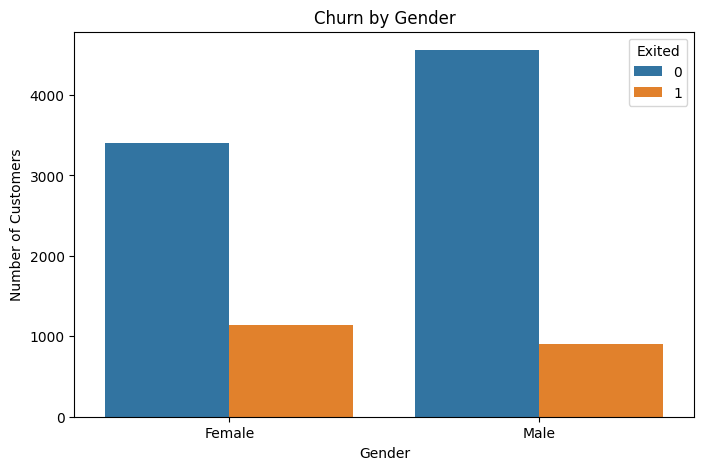

In [58]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="Gender",
    hue="Exited"
)
plt.title("Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

In [59]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 30, 40, 50, 60, 100],
    labels=["<30", "30-40", "40-50", "50-60", "60+"]
)

In [60]:
age_churn = pd.crosstab(
    df["AgeGroup"],
    df["Exited"],
    normalize="index"
) * 100

print(age_churn)

Exited            0          1
AgeGroup                      
<30       92.479675   7.520325
30-40     87.912829  12.087171
40-50     66.034483  33.965517
50-60     43.789210  56.210790
60+       75.215517  24.784483


In [61]:
active_churn = pd.crosstab(
    df["IsActiveMember"],
    df["Exited"],
    normalize="index"
) * 100

print(active_churn)

Exited                  0          1
IsActiveMember                      
0               73.149103  26.850897
1               85.730926  14.269074


In [62]:
products_churn = pd.crosstab(
    df["NumOfProducts"],
    df["Exited"],
    normalize="index"
) * 100

print(products_churn)

Exited                 0           1
NumOfProducts                       
1              72.285602   27.714398
2              92.418301    7.581699
3              17.293233   82.706767
4               0.000000  100.000000


In [63]:
tenure_churn = pd.crosstab(
    df["Tenure"],
    df["Exited"],
    normalize="index"
) * 100

print(tenure_churn)

Exited          0          1
Tenure                      
0       76.997579  23.002421
1       77.584541  22.415459
2       80.820611  19.179389
3       78.889990  21.110010
4       79.474216  20.525784
5       79.347826  20.652174
6       79.731127  20.268873
7       82.782101  17.217899
8       80.780488  19.219512
9       78.353659  21.646341
10      79.387755  20.612245


In [65]:
tenure_churn = pd.crosstab(
    df["Gender"],
    df["Exited"],
    normalize="index"
) * 100

print(tenure_churn)

Exited          0          1
Gender                      
Female  74.928461  25.071539
Male    83.544072  16.455928


In [66]:
print(df.groupby("Exited")[numerical_cols].mean().T)

Exited                      0              1
CreditScore        651.853196     645.351497
Age                 37.408389      44.837997
Tenure               5.033279       4.932744
Balance          72745.296779   91108.539337
NumOfProducts        1.544267       1.475209
EstimatedSalary  99738.391772  101465.677531


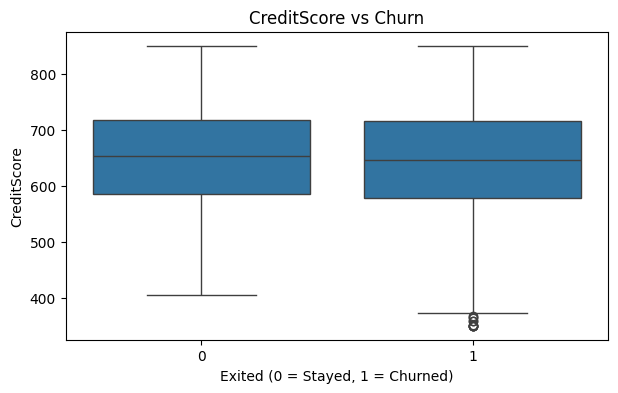

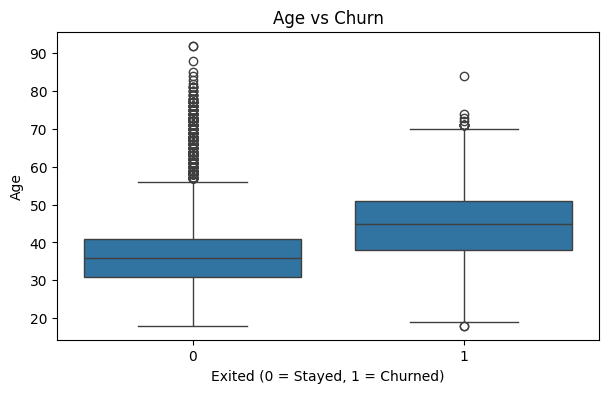

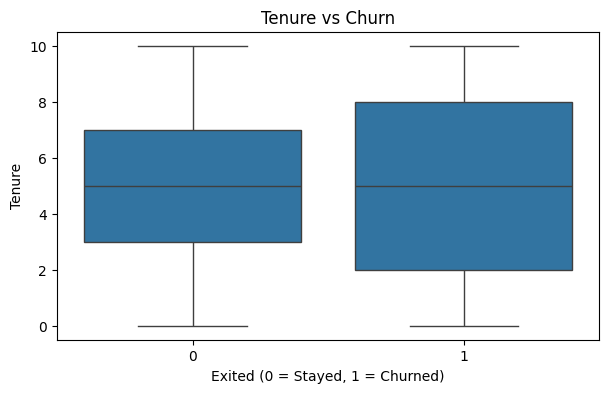

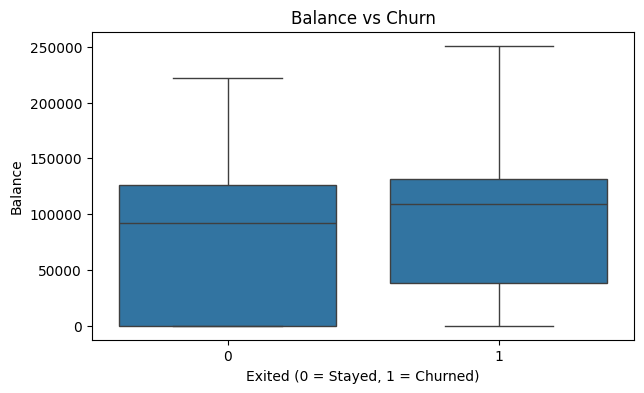

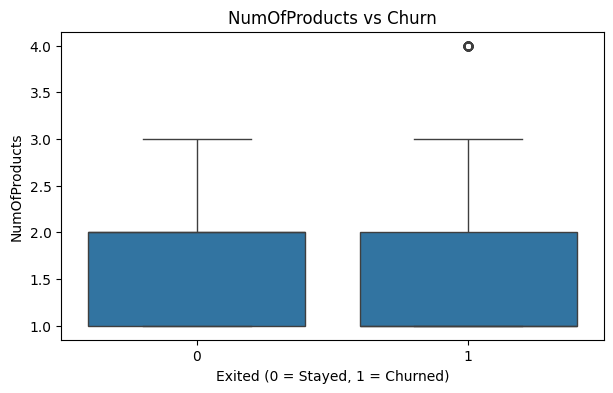

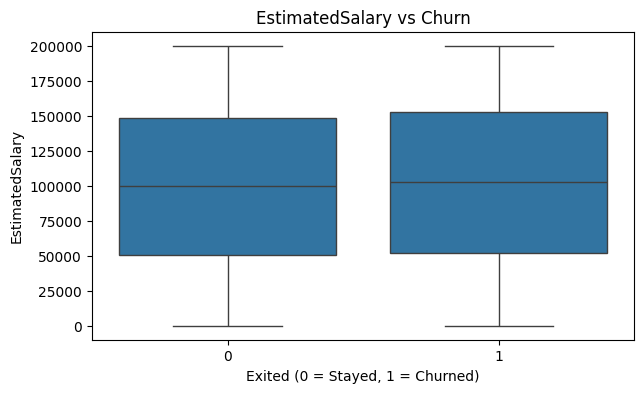

In [69]:
for col in numerical_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x="Exited", y=col, data=df)
    plt.title(f"{col} vs Churn")
    plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
    plt.ylabel(col)
    plt.show()


In [75]:
df = df.drop(columns=["AgeGroup"])

KeyError: "['AgeGroup'] not found in axis"

In [76]:
X = df.drop(columns=["Exited"])
y = df["Exited"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 10)
y shape: (10000,)


In [77]:
X = pd.get_dummies(
    X,
    columns=["Geography", "Gender"],
    drop_first=True
)

print(X.head())
print(X.shape)

   CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619   42       2       0.00              1          1   
1          608   41       1   83807.86              1          0   
2          502   42       8  159660.80              3          1   
3          699   39       1       0.00              2          0   
4          850   43       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Geography_Germany  Geography_Spain  \
0               1        101348.88              False            False   
1               1        112542.58              False             True   
2               0        113931.57              False            False   
3               0         93826.63              False            False   
4               1         79084.10              False             True   

   Gender_Male  
0        False  
1        False  
2        False  
3        False  
4        False  
(10000, 11)


In [88]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print("X_train shape:", X_train.shape)
print("Y_train shape:", Y_train.shape)
print("X_test shape:", X_test.shape)
print("Y_test shape:", Y_test.shape)

X_train shape: (8000, 11)
Y_train shape: (2000, 11)
X_test shape: (2000, 11)
Y_test shape: (2000,)


In [89]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

Training target distribution:
Exited
0    79.45
1    20.55
Name: proportion, dtype: float64


In [90]:
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)


Testing target distribution:
Exited
0    80.35
1    19.65
Name: proportion, dtype: float64


In [91]:
model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

In [92]:
model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [93]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

In [94]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", roc_auc)

Accuracy : 0.87
Precision: 0.7567567567567568
Recall   : 0.49872773536895676
F1 Score : 0.6012269938650306
ROC-AUC  : 0.8763916136622378


[[1544   63]
 [ 197  196]]


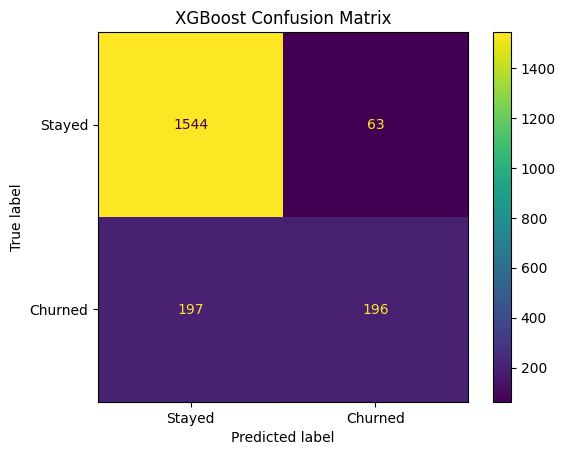

In [95]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot()
plt.title("XGBoost Confusion Matrix")
plt.show()

In [96]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Stayed:", negative)
print("Churned:", positive)
print("scale_pos_weight:", scale_pos_weight)

Stayed: 6356
Churned: 1644
scale_pos_weight: 3.8661800486618003


In [97]:
model_balanced = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss"
)

In [98]:
model_balanced.fit(
    X_train,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [99]:
y_pred_balanced = model_balanced.predict(X_test)
y_prob_balanced = model_balanced.predict_proba(X_test)[:, 1]

In [100]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy :", accuracy_score(y_test, y_pred_balanced))
print("Precision:", precision_score(y_test, y_pred_balanced))
print("Recall   :", recall_score(y_test, y_pred_balanced))
print("F1 Score :", f1_score(y_test, y_pred_balanced))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_balanced))

Accuracy : 0.825
Precision: 0.538878842676311
Recall   : 0.7582697201017812
F1 Score : 0.6300211416490487
ROC-AUC  : 0.8740355094046244


[[1352  255]
 [  95  298]]


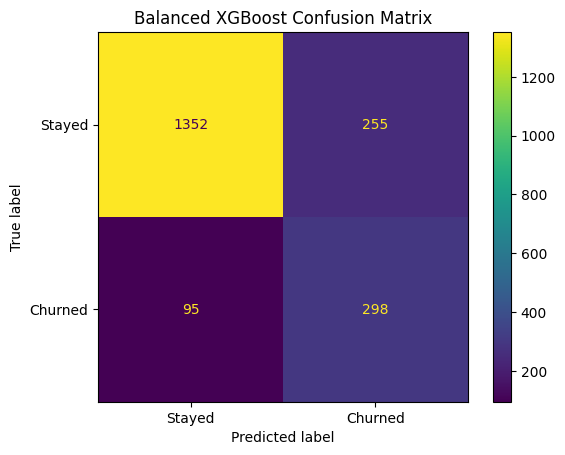

In [101]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_balanced = confusion_matrix(y_test, y_pred_balanced)

print(cm_balanced)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=["Stayed", "Churned"]
)

disp.plot()
plt.title("Balanced XGBoost Confusion Matrix")
plt.show()

In [102]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model_balanced.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance)

NumOfProducts        0.295447
Age                  0.149406
IsActiveMember       0.139353
Geography_Germany    0.100927
Balance              0.070095
Gender_Male          0.063000
Geography_Spain      0.044687
EstimatedSalary      0.037298
CreditScore          0.036886
HasCrCard            0.033076
Tenure               0.029826
dtype: float32


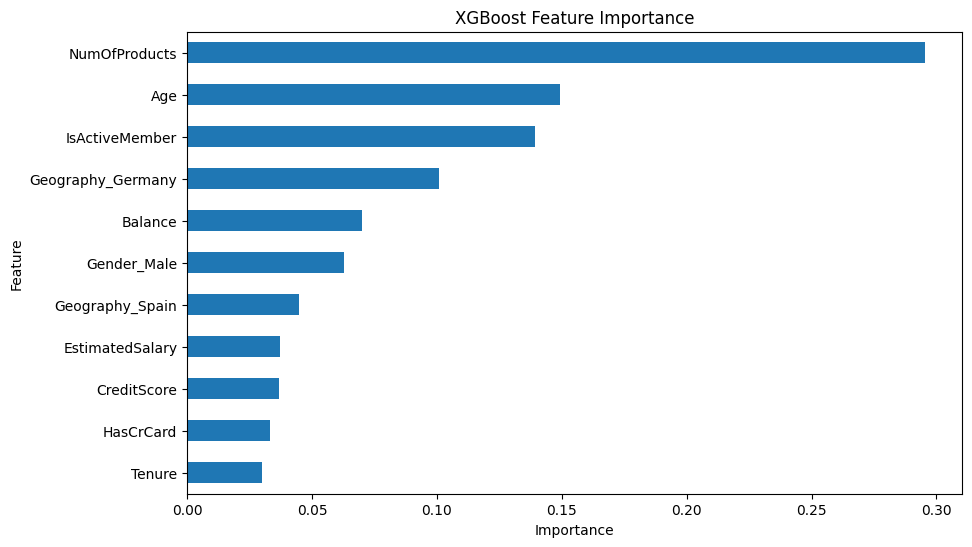

In [103]:
plt.figure(figsize=(10, 6))

importance.sort_values().plot(kind="barh")

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [104]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

param_grid = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [3, 4, 5, 6, 7],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.2, 0.3]
}

In [105]:
tuning_model = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss"
)

random_search = RandomizedSearchCV(
    estimator=tuning_model,
    param_distributions=param_grid,
    n_iter=20,
    scoring="f1",
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


RandomizedSearchCV(cv=3,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=True,
                                           eval_metric='logloss',
                                           feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_const...
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.8, 0.9,
                                                             1.0],
                                        'gamma': [0, 0.1, 0.2, 0.3],
                                        'learning_rate': [0.01, 0.03, 0.05,
                                                          0.1],
                                        'max_depth': [3, 4, 5, 6, 7],
                                        'min_child_weight': [1, 3, 5],
                                        'n_estimators': [100, 200, 300, 400],
                                        'subsample': [0.7, 0.8, 0.9, 1.0]},
                   random_state=42, scoring='f1', verbose=1)

In [106]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV F1 Score:")
print(random_search.best_score_)

Best Parameters:
{'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'gamma': 0.1, 'colsample_bytree': 0.8}

Best CV F1 Score:
0.610471477558316


In [108]:
best_model = random_search.best_estimator_


In [109]:
y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

In [110]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Tuned XGBoost Results")
print("---------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall   :", recall_score(y_test, y_pred_tuned))
print("F1 Score :", f1_score(y_test, y_pred_tuned))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_tuned))

Tuned XGBoost Results
---------------------
Accuracy : 0.821
Precision: 0.5305410122164049
Recall   : 0.7735368956743003
F1 Score : 0.629399585921325
ROC-AUC  : 0.8765879556837058


[[1338  269]
 [  89  304]]


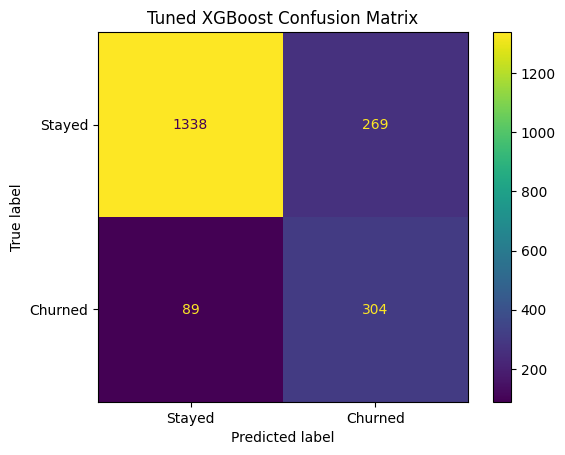

In [111]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_tuned = confusion_matrix(y_test, y_pred_tuned)

print(cm_tuned)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=["Stayed", "Churned"]
)

disp.plot()
plt.title("Tuned XGBoost Confusion Matrix")
plt.show()

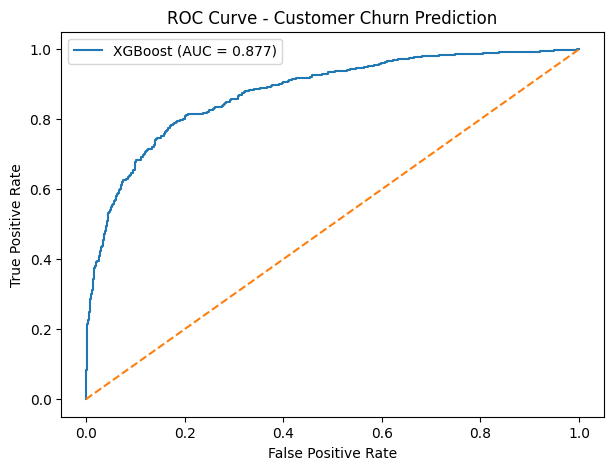

In [112]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_prob_tuned)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"XGBoost (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.show()

In [113]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Stayed", "Churned"]
))

              precision    recall  f1-score   support

      Stayed       0.94      0.83      0.88      1607
     Churned       0.53      0.77      0.63       393

    accuracy                           0.82      2000
   macro avg       0.73      0.80      0.76      2000
weighted avg       0.86      0.82      0.83      2000



In [114]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_tuned)

print(cm)

[[1338  269]
 [  89  304]]


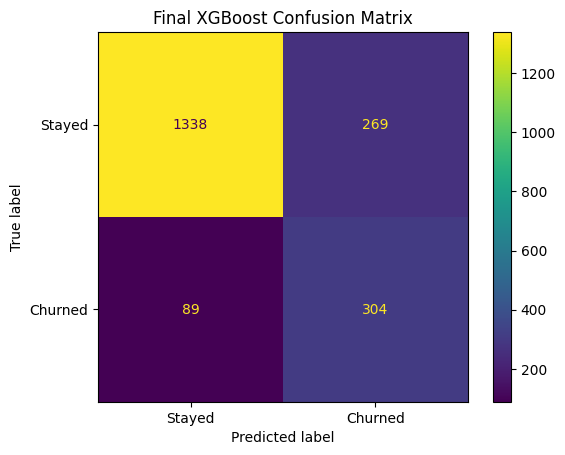

In [115]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot()
plt.title("Final XGBoost Confusion Matrix")
plt.show()

In [116]:
import joblib

joblib.dump(best_model, "customer_churn_xgboost.pkl")

print("Model saved successfully!")

Model saved successfully!
